In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import joblib

from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    RocCurveDisplay
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [2]:
PROCESSED_PATH = "../data/processed/"
MODEL_PATH = "../models/"

os.makedirs(MODEL_PATH, exist_ok=True)

play_features_path = (
    PROCESSED_PATH + "play_level_features.csv"
)

injury_features_path = (
    PROCESSED_PATH + "injury_enriched_features.csv"
)

In [3]:
play_features = pd.read_csv(
    play_features_path,
    dtype={
        "PlayKey": "string",
        "GameID": "string"
    }
)

injury_enriched = pd.read_csv(
    injury_features_path,
    dtype={"PlayKey": "string"}
)

print("Play-level dataset:", play_features.shape)
print("Injury-enriched dataset:", injury_enriched.shape)

display(play_features.head())

Play-level dataset: (267005, 34)
Injury-enriched dataset: (77, 41)


,PlayerKey,GameID,PlayKey,RosterPosition,PlayerDay,PlayerGame,StadiumType,FieldType,Temperature,Weather,...,y_max,duration,speed_mean,speed_std,acceleration_mean,acceleration_abs_mean,x_range,y_range,is_synthetic,temperature_category
0,26624,26624-1,26624-1-1,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,29.85,29.8,0.535753,0.607923,-0.000336,0.339262,7.13,6.23,1,Moderate
1,26624,26624-1,26624-1-2,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,29.96,25.9,0.849692,0.617141,0.041313,0.386486,10.18,2.61,1,Moderate
2,26624,26624-1,26624-1-3,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,29.63,29.5,0.331014,0.487729,0.043729,0.158983,4.33,3.89,1,Moderate
3,26624,26624-1,26624-1-4,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,27.71,12.6,0.523701,0.529241,0.075397,0.353175,3.09,3.08,1,Moderate
4,26624,26624-1,26624-1-5,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,26.41,25.9,0.970385,0.869971,0.049807,0.268340,20.47,4.48,1,Moderate


In [4]:
injured_playkeys = set(
    injury_enriched["PlayKey"]
    .dropna()
    .unique()
)

print("Unique injured PlayKeys:", len(injured_playkeys))
print("Total play records:", len(play_features))

Unique injured PlayKeys: 76
Total play records: 267005


In [5]:
# Each row represents a player-play record
model_data = play_features.copy()

# Avoid duplicate PlayKeys
assert model_data["PlayKey"].is_unique, (
    "Duplicate PlayKeys found in play_features."
)

# 1 = matched injury record
# 0 = no matched injury record
model_data["recorded_injury_label"] = (
    model_data["PlayKey"]
    .isin(injured_playkeys)
    .astype(int)
)

print(
    model_data["recorded_injury_label"]
    .value_counts()
)

display(
    model_data[
        ["PlayKey", "GameID", "FieldType",
         "recorded_injury_label"]
    ].head(10)
)

recorded_injury_label
0    266929
1        76
Name: count, dtype: int64


,PlayKey,GameID,FieldType,recorded_injury_label
0,26624-1-1,26624-1,synthetic,0
1,26624-1-2,26624-1,synthetic,0
2,26624-1-3,26624-1,synthetic,0
3,26624-1-4,26624-1,synthetic,0
4,26624-1-5,26624-1,synthetic,0
5,26624-1-6,26624-1,synthetic,0
6,26624-1-7,26624-1,synthetic,0
7,26624-1-8,26624-1,synthetic,0
8,26624-1-9,26624-1,synthetic,0
9,26624-1-10,26624-1,synthetic,0


Class counts:


recorded_injury_label
0    266929
1        76
Name: count, dtype: int64

Class percentages:


recorded_injury_label
0    99.971536
1     0.028464
Name: proportion, dtype: float64

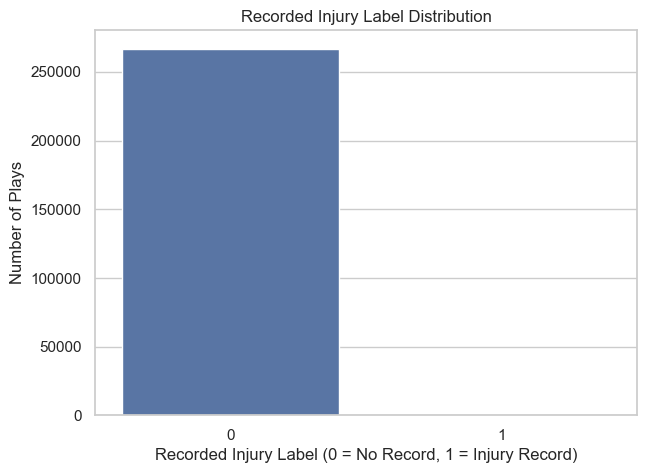

In [6]:
class_counts = model_data[
    "recorded_injury_label"
].value_counts().sort_index()

class_percentages = (
    model_data["recorded_injury_label"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Class counts:")
display(class_counts)

print("Class percentages:")
display(class_percentages)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=class_counts.index.astype(str),
    y=class_counts.values
)

plt.title("Recorded Injury Label Distribution")
plt.xlabel("Recorded Injury Label (0 = No Record, 1 = Injury Record)")
plt.ylabel("Number of Plays")

plt.show()

In [7]:
numeric_features = [
    "Temperature",
    "tracking_points",
    "duration",
    "distance_total",
    "speed_mean",
    "speed_max",
    "speed_std",
    "acceleration_mean",
    "acceleration_abs_mean",
    "acceleration_abs_max",
    "x_range",
    "y_range"
]

categorical_features = [
    "FieldType",
    "StadiumType",
    "Weather",
    "PlayType",
    "Position",
    "PositionGroup",
    "RosterPosition",
    "temperature_category"
]

# Keep only columns that actually exist
numeric_features = [
    col for col in numeric_features
    if col in model_data.columns
]

categorical_features = [
    col for col in categorical_features
    if col in model_data.columns
]

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['Temperature', 'tracking_points', 'duration', 'distance_total', 'speed_mean', 'speed_max', 'speed_std', 'acceleration_mean', 'acceleration_abs_mean', 'acceleration_abs_max', 'x_range', 'y_range']

Categorical features: ['FieldType', 'StadiumType', 'Weather', 'PlayType', 'Position', 'PositionGroup', 'RosterPosition', 'temperature_category']


In [8]:
feature_columns = (
    numeric_features + categorical_features
)

X = model_data[feature_columns].copy()

y = model_data["recorded_injury_label"].copy()

# Use GameID for grouped splitting, not as a feature
groups = model_data["GameID"].copy()

# Remove rows without a game identifier
valid_rows = groups.notna()

X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].reset_index(drop=True)
groups = groups.loc[valid_rows].reset_index(drop=True)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nUnique games:", groups.nunique())
print("\nPositive injury records:", y.sum())

X shape: (267005, 20)
y shape: (267005,)

Target distribution:
recorded_injury_label
0    266929
1        76
Name: count, dtype: int64

Unique games: 5712

Positive injury records: 76


In [9]:
positive_game_count = groups[y == 1].nunique()
negative_game_count = groups[y == 0].nunique()

print("Games containing recorded injury:", positive_game_count)
print("Games without recorded injury:", negative_game_count)

if positive_game_count >= 5 and negative_game_count >= 5:

    splitter = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    selected_split = None

    for train_idx, test_idx in splitter.split(
        X, y, groups
    ):
        if (
            y.iloc[train_idx].nunique() == 2
            and y.iloc[test_idx].nunique() == 2
        ):
            selected_split = (train_idx, test_idx)
            break

    if selected_split is None:
        raise ValueError(
            "No grouped fold contains both classes. "
            "We need to inspect the distribution of injury records across games."
        )

    train_idx, test_idx = selected_split

else:
    raise ValueError(
        "There are fewer than 5 games in one of the classes. "
        "A 5-fold stratified group split is not suitable. "
        "Inspect the class distribution before choosing another evaluation method."
    )

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

print(
    "\nTraining games:",
    groups.iloc[train_idx].nunique()
)

print(
    "Testing games:",
    groups.iloc[test_idx].nunique()
)

assert set(groups.iloc[train_idx]).isdisjoint(
    set(groups.iloc[test_idx])
)

Games containing recorded injury: 76
Games without recorded injury: 5709
Training shape: (213604, 20)
Testing shape: (53401, 20)

Training labels:
recorded_injury_label
0    213543
1        61
Name: count, dtype: int64

Testing labels:
recorded_injury_label
0    53386
1       15
Name: count, dtype: int64

Training games: 4571
Testing games: 1141


In [10]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [11]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                solver="liblinear",
                random_state=42
            )
        )
    ]
)

In [12]:
logistic_model.fit(
    X_train,
    y_train
)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [13]:
y_pred = logistic_model.predict(X_test)

y_probability = logistic_model.predict_proba(
    X_test
)[:, 1]

print("Predictions generated.")

display(
    pd.DataFrame({
        "Actual": y_test.values[:10],
        "Predicted": y_pred[:10],
        "Injury_Record_Probability": y_probability[:10]
    })
)

Predictions generated.


,Actual,Predicted,Injury_Record_Probability
0,0,0,0.000005
1,0,0,0.000012
2,0,0,0.000009
3,0,0,0.000009
4,0,0,0.000011
5,0,0,0.000008
6,0,0,0.000003
7,0,0,0.000018
8,0,0,0.000007
9,0,0,0.000004


In [14]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Injury Record",
            "Injury Record"
        ],
        zero_division=0
    )
)

                  precision    recall  f1-score   support

No Injury Record       1.00      0.82      0.90     53386
   Injury Record       0.00      0.40      0.00        15

        accuracy                           0.82     53401
       macro avg       0.50      0.61      0.45     53401
    weighted avg       1.00      0.82      0.90     53401



In [15]:
roc_auc = roc_auc_score(
    y_test,
    y_probability
)

pr_auc = average_precision_score(
    y_test,
    y_probability
)

print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))

print(
    "Test-set positive class prevalence:",
    round(y_test.mean(), 4)
)

ROC-AUC: 0.6889
PR-AUC: 0.0007
Test-set positive class prevalence: 0.0003


,Predicted 0,Predicted 1
Actual 0,43749,9637
Actual 1,9,6


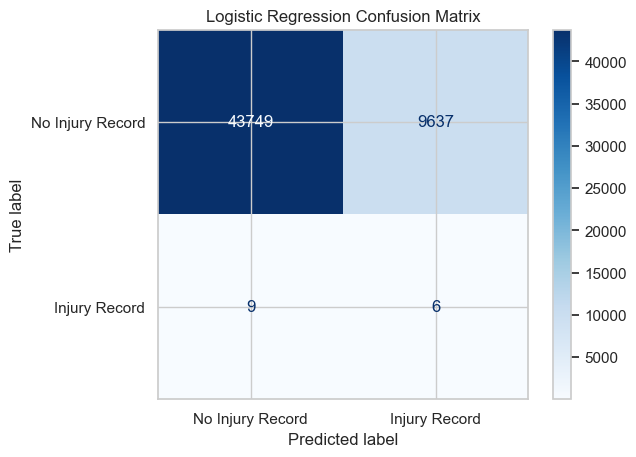

In [16]:
cm = confusion_matrix(
    y_test,
    y_pred
)

display(
    pd.DataFrame(
        cm,
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    )
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No Injury Record",
        "Injury Record"
    ]
).plot(cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")
plt.show()

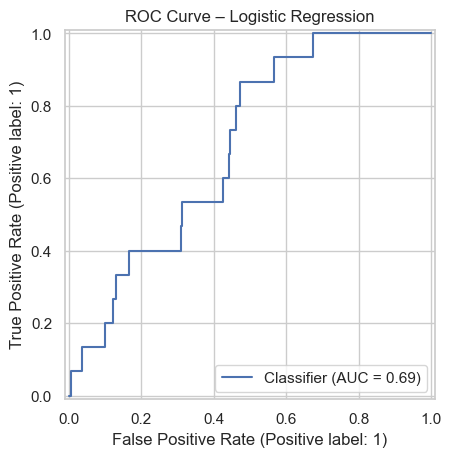

In [17]:
RocCurveDisplay.from_predictions(
    y_test,
    y_probability
)

plt.title("ROC Curve – Logistic Regression")
plt.show()

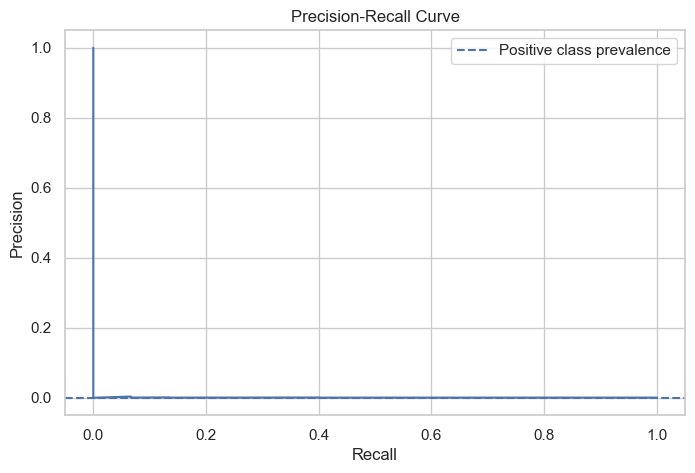

In [18]:
precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(8, 5))

plt.plot(recall, precision)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    label="Positive class prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")

plt.legend()
plt.show()

In [19]:
dummy_model = DummyClassifier(
    strategy="prior"
)

dummy_model.fit(
    X_train,
    y_train
)

dummy_probability = dummy_model.predict_proba(
    X_test
)[:, 1]

dummy_pr_auc = average_precision_score(
    y_test,
    dummy_probability
)

print("Dummy model PR-AUC:", round(dummy_pr_auc, 4))
print("Logistic Regression PR-AUC:", round(pr_auc, 4))

Dummy model PR-AUC: 0.0003
Logistic Regression PR-AUC: 0.0007


In [20]:
fitted_preprocessor = (
    logistic_model.named_steps["preprocessor"]
)

feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

coefficients = (
    logistic_model.named_steps["classifier"].coef_[0]
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Importance": np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    "Absolute_Importance",
    ascending=False
)

display(feature_importance.head(20))

,Feature,Coefficient,Absolute_Importance
2,num__duration,-11.076649,11.076649
1,num__tracking_points,11.027092,11.027092
26,"cat__StadiumType_Indoor, Roof Closed",10.616438,10.616438
15,cat__StadiumType_Closed Dome,10.532352,10.532352
21,"cat__StadiumType_Domed, closed",7.758974,7.758974
70,cat__Weather_Indoor,7.529556,7.529556
58,"cat__Weather_Cloudy, 50% change of rain",7.443152,7.443152
22,"cat__StadiumType_Domed, open",-6.739839,6.739839
24,cat__StadiumType_Indoor,6.477776,6.477776
66,cat__Weather_Fair,6.278673,6.278673


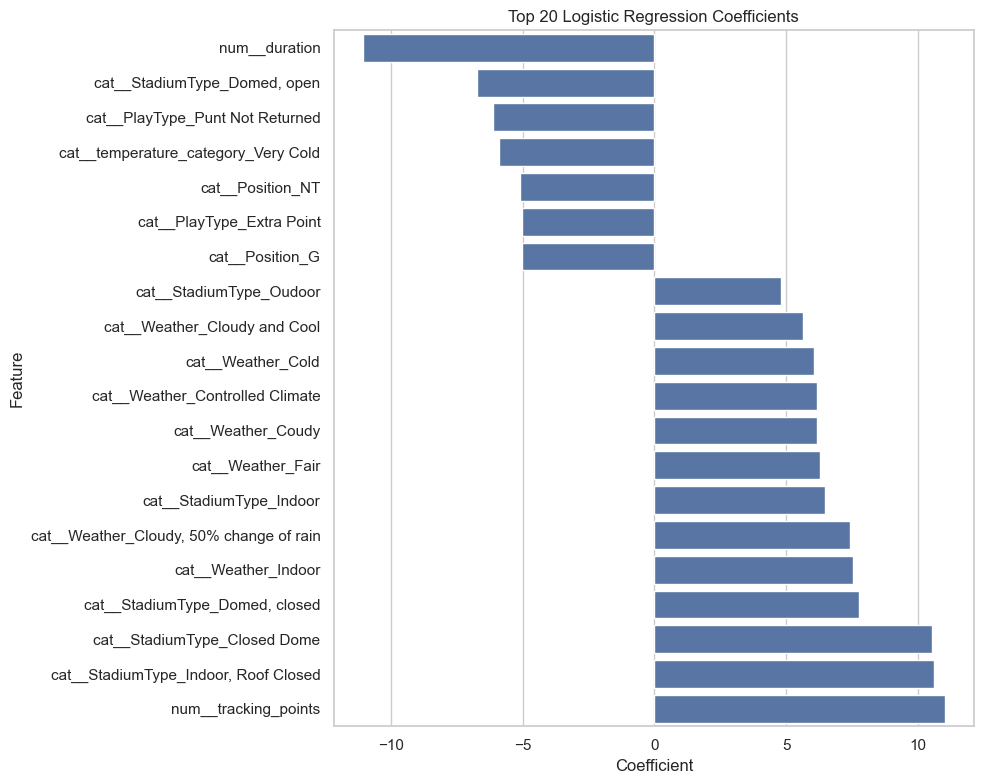

In [21]:
top_features = feature_importance.head(20).sort_values(
    "Coefficient"
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature"
)

plt.title("Top 20 Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [22]:
joblib.dump(
    logistic_model,
    MODEL_PATH + "turfguard_logistic_model.pkl"
)

print("Model saved successfully.")

Model saved successfully.


In [23]:
test_predictions = pd.DataFrame({
    "Actual_Label": y_test.values,
    "Predicted_Label": y_pred,
    "Injury_Record_Probability": y_probability
})

test_predictions.to_csv(
    PROCESSED_PATH + "model_test_predictions.csv",
    index=False
)

print("Test predictions saved.")

Test predictions saved.


In [ ]:
evaluation_results = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression"
    ],
    "PR_AUC": [
        dummy_pr_auc,
        pr_auc
    ],
    "ROC_AUC": [
        np.nan,
        roc_auc
    ]
})

display(evaluation_results)

evaluation_results.to_csv(
    PROCESSED_PATH + "model_evaluation_results.csv",
    index=False
)

,Model,PR_AUC,ROC_AUC
0,Dummy Classifier,0.000281,NaN
1,Logistic Regression,0.000742,0.688895


: 